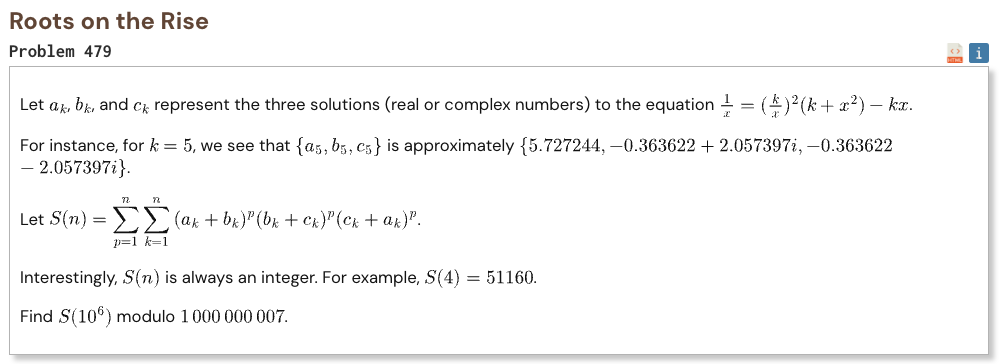

## Initial approach

- use the cubic equation to get the sum and products of its three roots without solving for the roots directly
- rewrite the product of the three pair sums using symmetric polynomial identities
- this simplifies every inner term to a power of 1 - k²
- for each k the sum over p is just a geometric series
- calculate that geometric series modulo one billion and seven
- precompute modular inverses up to one million so division by k² is fast
- loop over all k values and add their contributions modulo the required modulus

In [1]:
%%time

MOD = 1_000_000_007
n = 1_000_000

inverse = [0] * (n + 1)
inverse[1] = 1

for k in range(2, n + 1):
    inverse[k] = (
        MOD
        - (MOD // k) * inverse[MOD % k] % MOD
    )

result = 0

for k in range(2, n + 1):
    k2 = k * k % MOD
    r = (1 - k2) % MOD

    geometric = (
        (k2 - 1)
        * (pow(r, n, MOD) - 1)
        % MOD
    )

    geometric = (
        geometric
        * inverse[k]
        % MOD
        * inverse[k]
        % MOD
    )

    result = (result + geometric) % MOD

print("Result:", result)

Result: 191541795
CPU times: user 1.11 s, sys: 11.3 ms, total: 1.12 s
Wall time: 1.13 s
